# N6 — Mechanism and mitigation

Two experiments. E1 needs no training; E2 is one training run.

### Why these two

The literature already establishes that augmentation does not transfer across corruption types
(Geirhos et al. 2018; Vasiljevic et al. 2016; Mintun et al., NeurIPS 2021). Reporting the colour
effect on its own would be a domain replication, not a contribution.

**E1 turns three points into a mechanism.** You have grey/white/black. Nine intensities give a
curve, and the curve's *shape* distinguishes two hypotheses:

| shape | mechanism |
|---|---|
| **V centred on 127** | the model memorised the training intensity |
| **monotonic toward black** | the model learned "occluder = region unlike marker structure"; black resembles marker ink and the black border, so it is not flagged |

**E2 turns a failure into a fix.** Train the same network sampling occluder intensity uniformly
instead of fixing it at grey. If the curve flattens, you have problem, mechanism and remedy —
which is a contribution even when the phenomenon is known, because the remedy is specific and
actionable for marker pipelines.

### Already ruled out

Min-max normalisation. Verified offline: the crop's min stays 0 and max 255 at every occluder
intensity, because the marker retains black and white cells either way. Preprocessing is not the
cause.

The published decoder A is nearly flat across occluder intensity (mean Hamming 5.50-6.75 at 45%
occlusion). Colour sensitivity is **acquired through augmentation**, not intrinsic to the task.
A therefore serves as the control curve.

## 1. Setup

In [1]:
!pip -q install opencv-contrib-python==4.10.0.84 h5py 2>&1 | tail -1
print(">>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 8.8 MB/s eta 0:00:00
>>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.


### 1b. Port module

In [1]:
%%writefile /content/deeparuco_port.py
"""
Port the pretrained DeepArUco++ decoder from Keras .h5 to PyTorch, without TensorFlow.

The published decoder (models/dec_new.h5 in AVAuco/deeparuco) is a Keras 2.11 model:

    Input(32, 32, 1)
    Conv2D(8, 5x5, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(4, 3x3, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(1, 1x1, valid, sigmoid)   ->  (6, 6, 1)

Only h5py is needed to read the weights, so the repo's Python 3.9 + TensorFlow
environment is never required for baseline inference.

IMPORTANT PORTING DETAIL
    Keras PReLU defaults to shared_axes=None, so alpha is PER-ELEMENT, not per-channel:
    the stored alphas have shape (28, 28, 8) and (12, 12, 4). torch.nn.PReLU only
    supports per-channel alpha, so using it here silently produces a different model.
    SpatialPReLU below keeps the full alpha tensor.

Layout conversions:
    Keras conv kernel (kh, kw, in, out) -> torch (out, in, kh, kw)
    Keras PReLU alpha (h, w, c)         -> torch (c, h, w)
    Keras 'valid' padding               -> torch padding=0

Usage:
    from deeparuco_port import load_weights, NumpyDecoder, TorchDecoder, verify_port
    verify_port('models/dec_new.h5')          # run this first, once
    dec = TorchDecoder.from_h5('models/dec_new.h5')
    probs = dec(x)                            # x: (N, 1, 32, 32) float in [0, 1]

Upstream code is AGPL-3.0. This module reads a weights file; it does not copy source.
Cite Berral-Soler et al., Image and Vision Computing 152 (2024) 105313.
"""

import numpy as np

DEFAULT_H5 = "models/dec_new.h5"


# --------------------------------------------------------------------------- weights

def load_weights(h5_path=DEFAULT_H5):
    """Read decoder weights from the Keras .h5. Returns a dict of numpy arrays."""
    import h5py

    store = {}
    with h5py.File(h5_path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset) and name.startswith("model_weights/"):
                store[name] = np.array(obj)
        f.visititems(visit)

    def pick(layer, suffix):
        hits = [k for k in store if f"/{layer}/" in k and k.endswith(suffix)]
        if len(hits) != 1:
            raise KeyError(f"expected one match for {layer}:{suffix}, got {hits}")
        return store[hits[0]]

    w = {
        "c1_w": pick("conv2d", "kernel:0"),   "c1_b": pick("conv2d", "bias:0"),
        "p1_a": pick("p_re_lu", "alpha:0"),
        "c2_w": pick("conv2d_1", "kernel:0"), "c2_b": pick("conv2d_1", "bias:0"),
        "p2_a": pick("p_re_lu_1", "alpha:0"),
        "c3_w": pick("conv2d_2", "kernel:0"), "c3_b": pick("conv2d_2", "bias:0"),
    }
    expect = {"c1_w": (5,5,1,8), "c1_b": (8,), "p1_a": (28,28,8),
              "c2_w": (3,3,8,4), "c2_b": (4,), "p2_a": (12,12,4),
              "c3_w": (1,1,4,1), "c3_b": (1,)}
    for k, shape in expect.items():
        assert w[k].shape == shape, f"{k}: got {w[k].shape}, expected {shape}"
    return w


# ------------------------------------------------------------------- numpy reference

class NumpyDecoder:
    """Reference implementation. Verified against synthetic markers: 4/5 exact."""

    def __init__(self, weights):
        self.w = weights

    @classmethod
    def from_h5(cls, path=DEFAULT_H5):
        return cls(load_weights(path))

    @staticmethod
    def _conv(x, w, b):
        kh, kw, _, co = w.shape
        H, W, _ = x.shape
        out = np.zeros((H - kh + 1, W - kw + 1, co), np.float32)
        for i in range(out.shape[0]):
            for j in range(out.shape[1]):
                out[i, j] = np.tensordot(
                    x[i:i+kh, j:j+kw, :], w, axes=([0, 1, 2], [0, 1, 2])) + b
        return out

    @staticmethod
    def _pool(x):
        h, w, c = x.shape
        return x.reshape(h // 2, 2, w // 2, 2, c).max(axis=(1, 3))

    def __call__(self, marker32):
        """marker32: (32, 32) float in [0, 1]. Returns (6, 6) bit probabilities."""
        w = self.w
        x = np.asarray(marker32, np.float32)[..., None]
        x = self._conv(x, w["c1_w"], w["c1_b"])
        x = np.where(x > 0, x, w["p1_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c2_w"], w["c2_b"])
        x = np.where(x > 0, x, w["p2_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c3_w"], w["c3_b"])
        return (1.0 / (1.0 + np.exp(-np.clip(x[..., 0], -60, 60)))).astype(np.float32)


# -------------------------------------------------------------------------- pytorch

def _torch():
    import torch
    import torch.nn as nn
    return torch, nn


class SpatialPReLU:
    """Created via _build so torch is imported lazily. See module docstring."""


def TorchDecoder_factory():
    torch, nn = _torch()

    class _SpatialPReLU(nn.Module):
        """Per-element PReLU, matching Keras PReLU(shared_axes=None)."""
        def __init__(self, alpha_chw):
            super().__init__()
            self.alpha = nn.Parameter(torch.tensor(alpha_chw, dtype=torch.float32))

        def forward(self, x):
            return torch.where(x > 0, x, self.alpha.unsqueeze(0) * x)

    class _TorchDecoder(nn.Module):
        def __init__(self, weights=None):
            super().__init__()
            self.c1 = nn.Conv2d(1, 8, 5)
            self.c2 = nn.Conv2d(8, 4, 3)
            self.c3 = nn.Conv2d(4, 1, 1)
            self.pool = nn.MaxPool2d(2)
            a1 = np.zeros((8, 28, 28), np.float32) if weights is None \
                 else np.transpose(weights["p1_a"], (2, 0, 1))
            a2 = np.zeros((4, 12, 12), np.float32) if weights is None \
                 else np.transpose(weights["p2_a"], (2, 0, 1))
            self.p1, self.p2 = _SpatialPReLU(a1), _SpatialPReLU(a2)
            if weights is not None:
                self.load_keras(weights)

        def load_keras(self, w):
            with torch.no_grad():
                for conv, kw, kb in ((self.c1, "c1_w", "c1_b"),
                                     (self.c2, "c2_w", "c2_b"),
                                     (self.c3, "c3_w", "c3_b")):
                    conv.weight.copy_(torch.tensor(np.transpose(w[kw], (3, 2, 0, 1))))
                    conv.bias.copy_(torch.tensor(w[kb]))

        @classmethod
        def from_h5(cls, path=DEFAULT_H5):
            return cls(load_weights(path))

        def forward(self, x):
            """x: (N, 1, 32, 32) in [0, 1]. Returns (N, 6, 6) bit probabilities."""
            x = self.pool(self.p1(self.c1(x)))
            x = self.pool(self.p2(self.c2(x)))
            return torch.sigmoid(self.c3(x)).squeeze(1)

    return _TorchDecoder


def __getattr__(name):
    if name == "TorchDecoder":
        return TorchDecoder_factory()
    raise AttributeError(name)


# --------------------------------------------------------------------------- verify

def verify_port(h5_path=DEFAULT_H5, n=16, tol=1e-4, verbose=True):
    """Assert the PyTorch port matches the numpy reference. Run once before use.

    The numpy path is validated; the torch path is validated against it here rather
    than assumed. Do not skip this.
    """
    torch, _ = _torch()
    w = load_weights(h5_path)
    ref = NumpyDecoder(w)
    net = TorchDecoder_factory()(w).eval()

    rng = np.random.default_rng(0)
    x = rng.random((n, 32, 32)).astype(np.float32)
    with torch.no_grad():
        got = net(torch.tensor(x).unsqueeze(1)).numpy()
    want = np.stack([ref(xi) for xi in x])

    err = float(np.abs(got - want).max())
    if verbose:
        print(f"port check: {n} random inputs, max abs difference {err:.2e} (tol {tol:g})")
    assert err < tol, f"PyTorch port disagrees with numpy reference (max diff {err:.2e})"
    if verbose:
        print("PyTorch port matches the numpy reference.")
    return err


def decode_ids(probs, id_to_bits, n_markers=250):
    """Hard-decision decode: nearest codeword by Hamming distance over 4 rotations.

    probs: (6, 6) bit probabilities. Returns (marker_id, rotation, hamming).
    Replace with soft log-likelihood decoding to use the confidences.
    """
    obs = (np.asarray(probs) > 0.5).astype(np.uint8)
    best = (None, None, 99)
    for mid in range(n_markers):
        ref = np.asarray(id_to_bits(mid), np.uint8).reshape(6, 6)
        for rot in range(4):
            h = int(np.sum(np.rot90(obs, rot) != ref))
            if h < best[2]:
                best = (mid, rot, h)
    return best


if __name__ == "__main__":
    import sys
    path = sys.argv[1] if len(sys.argv) > 1 else DEFAULT_H5
    w = load_weights(path)
    print("weights loaded:", {k: v.shape for k, v in w.items()})
    try:
        verify_port(path)
    except ImportError:
        print("torch not installed; numpy reference verified only")


Writing /content/deeparuco_port.py


In [2]:
import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive
drive.mount('/content/drive')

BASE  = '/content/drive/MyDrive/aruco_p2'
ART, WORK, CACHE, CKPT = f'{BASE}/artifacts', '/content/work', f'{BASE}/archives', f'{BASE}/ckpt_n3b'
CK6 = f'{BASE}/ckpt_n6'; os.makedirs(CK6, exist_ok=True); os.makedirs(WORK, exist_ok=True)
sys.path.insert(0, '/content')

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/AVAuco/deeparuco.git',REPO],check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits
from deeparuco_port import load_weights

DEV_ = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42); np.random.seed(42)
print('torch', torch.__version__, '| device', DEV_)
if DEV_.type != 'cuda':
    print('*** CPU runtime — E2 training will be very slow. Switch to T4 GPU.')

splits = json.load(open(f'{ART}/splits.json'))
DEV, HELDOUT, STRIDE = splits['dev'], splits['heldout'][0], splits['benchmark_stride']
assert HELDOUT not in DEV
Wk  = load_weights(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)

SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
FLY = f'{WORK}/flyingarucov2'
if not os.path.isdir(FLY):
    os.makedirs(FLY, exist_ok=True)
    subprocess.run(['tar','-xzf',f'{CACHE}/flyingarucov2.tar.gz','-C',FLY], check=True)
fly_json = sorted(glob.glob(f'{FLY}/**/*.json', recursive=True))
print('dev:', DEV, '| held out:', HELDOUT, '| flying-aruco:', len(fly_json))

Mounted at /content/drive
torch 2.11.0+cpu | device cpu
*** CPU runtime — E2 training will be very slow. Switch to T4 GPU.
dev: ['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] | held out: video_6 | flying-aruco: 2500


## 2. Pipeline — identical to N3b/N5, with occluder intensity as a parameter

In [3]:
r_int = lambda v: int(round(v))

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]
def warp32(crop, c, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))
def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)
def cell_occlusion(m32):
    s = 32/8.0; out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            out[r,c] = m32[int((r+1)*s):int((r+2)*s), int((c+1)*s):int((c+2)*s)].mean() > 127.5
    return out
def prepare(img, mask, corners):
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    crop = cv2.resize(img[sl], (64,64)).astype(np.float32)
    crop = (crop - crop.min())/(crop.max()-crop.min()+1e-9)
    nc = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    m32 = warp32(cv2.resize(mask[sl],(64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    return warp32(crop, nc), cell_occlusion(m32)
def occluder_box(img, corners, level, position, key, mid):
    if level <= 0: return None
    x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    if position == 'edge':
        side = int(np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode())).integers(0,4))
        box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
               (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    else:
        cx, cy = (x0+x1)/2, (y0+y1)/2
        box = (cx-level*w/2, cy-level*h/2, cx+level*w/2, cy+level*h/2)
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    return (a,b,c,d) if (c>a and d>b) else None
def apply_occluder(img, box, value):
    """value is now a raw intensity 0-255, not a colour name."""
    if box is None: return img, np.zeros(img.shape[:2], np.uint8)
    a,b,c,d = box
    out = img.copy(); mk = np.zeros(img.shape[:2], np.uint8)
    out[b:d,a:c] = int(value); mk[b:d,a:c] = 255
    return out, mk
def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out

class SpatialPReLU(nn.Module):
    def __init__(s,c,h,w): super().__init__(); s.a = nn.Parameter(torch.zeros(c,h,w))
    def forward(s,x): return torch.where(x>0, x, s.a.unsqueeze(0)*x)
class Decoder(nn.Module):
    def __init__(s, out_ch=1):
        super().__init__()
        s.c1=nn.Conv2d(1,8,5); s.p1=SpatialPReLU(8,28,28)
        s.c2=nn.Conv2d(8,4,3); s.p2=SpatialPReLU(4,12,12)
        s.c3=nn.Conv2d(4,out_ch,1); s.out_ch=out_ch
    def forward(s,x):
        x=F.max_pool2d(s.p1(s.c1(x)),2); x=F.max_pool2d(s.p2(s.c2(x)),2); x=s.c3(x)
        return (x[:,0], x[:,1]) if s.out_ch==2 else (x[:,0], None)

models = {}
for arm, oc in [('B',1), ('D',2)]:
    p = f'{CKPT}/arm_{arm}.pt'
    assert os.path.exists(p), f'{p} missing — run N3b first'
    n = Decoder(oc).to(DEV_); n.load_state_dict(torch.load(p, map_location=DEV_)); n.eval()
    models[arm] = n
print('arms B and D loaded from N3b')

arms B and D loaded from N3b


## 3. Decoding

In [4]:
def _conv(x,w,b):
    kh,kw,_,_ = w.shape
    return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
def _pool(x):
    N,H,Wd,Cc = x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
def decode_published(x8, chunk=4096):
    out=[]
    for s in range(0,len(x8),chunk):
        x = x8[s:s+chunk].astype(np.float32)[...,None]/255.0
        x = _pool(np.where((y:=_conv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
        x = _pool(np.where((y:=_conv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
        out.append(1/(1+np.exp(-np.clip(_conv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60))))
    return np.concatenate(out).astype(np.float32)
def decode_torch(net, x8, chunk=8192):
    ps=[]
    with torch.no_grad():
        for s in range(0,len(x8),chunk):
            xb = torch.tensor(x8[s:s+chunk], dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
            ps.append(torch.sigmoid(net(xb)[0]).cpu().numpy())
    return np.concatenate(ps)
def dec_soft(P):
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)
def paired(a,b,frames,n_boot=2000,seed=0):
    rng=np.random.default_rng(seed); uf,inv=np.unique(frames,return_inverse=True)
    by=[np.where(inv==i)[0] for i in range(len(uf))]
    d=np.empty(n_boot)
    for i in range(n_boot):
        idx=np.concatenate([by[p] for p in rng.integers(0,len(by),len(by))])
        d[i]=a[idx].mean()-b[idx].mean()
    return a.mean()-b.mean(), float(np.percentile(d,2.5)), float(np.percentile(d,97.5))
print('ready')

ready


## 4. E1 — Build the intensity sweep

Nine occluder intensities at three severities, edge position. Geometry is identical across
intensities by construction, so intensity is the only variable.

In [5]:
INTENS  = [0, 32, 64, 96, 127, 160, 192, 224, 255]
LEVELS  = {6: 0.30, 12: 0.40, 18: 0.50}     # nominal levels from N5 calibration (edge)

SWEEP = {(T,v): {'x':[], 'id':[], 'frame':[], 'occ':[]} for T in LEVELS for v in INTENS}
t0=time.time()
for vid in DEV:
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            for T, L in LEVELS.items():
                box = occluder_box(img, cn, L, 'edge', key, mid)
                for v in INTENS:
                    oi, om = apply_occluder(img, box, v)
                    x32, occ = prepare(oi, om, cn)
                    if x32 is None: continue
                    s = SWEEP[(T,v)]
                    s['x'].append((x32*255).astype(np.uint8)); s['id'].append(mid)
                    s['frame'].append(key); s['occ'].append(occ.sum())
    print(f'  {vid} ({time.time()-t0:.0f}s)')
for k in SWEEP:
    for kk in SWEEP[k]: SWEEP[k][kk] = np.array(SWEEP[k][kk])
print(f'\n{len(SWEEP[(6,0)]["id"])} markers per cell, {len(SWEEP)} cells')
print('occluded cells per severity:',
      {T: round(float(SWEEP[(T,127)]['occ'].mean()),1) for T in LEVELS})

  video_1 (86s)
  video_2 (147s)
  video_3 (226s)
  video_4 (321s)
  video_5 (387s)

12276 markers per cell, 27 cells
occluded cells per severity: {6: 5.8, 12: 11.5, 18: 18.0}


## 5. E1 — Evaluate A, B, D across intensity

The shape of B's curve is the result. A is the control: it never saw occlusion, so a flat A curve
confirms that colour sensitivity is acquired rather than intrinsic.

In [6]:
E1 = {}
for T in LEVELS:
    for v in INTENS:
        s = SWEEP[(T,v)]
        E1[(T,v)] = {
            'A': (dec_soft(decode_published(s['x'])) == s['id']),
            'B': (dec_soft(decode_torch(models['B'], s['x'])) == s['id']),
            'D': (dec_soft(decode_torch(models['D'], s['x'])) == s['id']),
        }
    print(f'  severity {T} done')

for arm in ('A','B','D'):
    print(f'\n--- arm {arm}: ID accuracy vs occluder intensity (edge) ---')
    print(f"{'cells':>6}" + ''.join(f'{v:>8}' for v in INTENS) + f"{'spread':>9}")
    print('-'*(6+8*len(INTENS)+9))
    for T in LEVELS:
        acc = [E1[(T,v)][arm].mean() for v in INTENS]
        print(f'{T:>6}' + ''.join(f'{a:>8.1%}' for a in acc) + f'{(max(acc)-min(acc))*100:>8.1f}p')

  severity 6 done
  severity 12 done
  severity 18 done

--- arm A: ID accuracy vs occluder intensity (edge) ---
 cells       0      32      64      96     127     160     192     224     255   spread
---------------------------------------------------------------------------------------
     6   92.5%   90.2%   84.4%   79.6%   75.4%   71.9%   68.3%   65.1%   62.9%    29.6p
    12   73.4%   72.2%   62.5%   54.6%   49.3%   45.1%   41.8%   38.8%   36.2%    37.2p
    18   44.5%   42.4%   32.3%   26.6%   22.7%   19.3%   16.6%   14.9%   13.9%    30.6p

--- arm B: ID accuracy vs occluder intensity (edge) ---
 cells       0      32      64      96     127     160     192     224     255   spread
---------------------------------------------------------------------------------------
     6   79.2%   98.0%   97.8%   97.8%   96.5%   94.9%   92.7%   90.2%   88.4%    18.8p
    12   58.7%   95.3%   96.1%   95.7%   93.0%   90.6%   87.7%   84.7%   82.8%    37.3p
    18   38.2%   84.9%   87.0%   86.6%

## 6. E1 — Which mechanism?

A V centred on 127 means the model memorised the training intensity. A monotonic decline toward
black means it learned "occluder = region unlike marker structure", and black resembles the
marker's ink and border so it goes unflagged. These imply different fixes, so the shape matters.

In [7]:
print('Testing curve shape for arm B\n')
for T in LEVELS:
    acc = np.array([E1[(T,v)]['B'].mean() for v in INTENS])
    x = np.array(INTENS, float)
    argmax_v = INTENS[int(acc.argmax())]
    # monotonic increasing in intensity?
    mono = np.all(np.diff(acc) >= -0.01)
    # V shape: best at 127, worse at both ends
    v_shape = (argmax_v in (96,127,160)) and acc[0] < acc[4]-0.02 and acc[-1] < acc[4]-0.02
    corr = float(np.corrcoef(x, acc)[0,1])
    print(f'severity {T:>2} cells:')
    print(f'  best intensity   : {argmax_v}   (training intensity was 127)')
    print(f'  worst intensity  : {INTENS[int(acc.argmin())]}')
    print(f'  monotonic in v   : {mono}')
    print(f'  V-shaped at 127  : {v_shape}')
    print(f'  corr(intensity,acc): {corr:+.3f}')
    d, lo, hi = paired(E1[(T,255)]['B'], E1[(T,0)]['B'], SWEEP[(T,0)]['frame'])
    print(f'  white - black    : {d*100:+.1f} pp [{lo*100:+.1f},{hi*100:+.1f}]\n')

sa = [max(E1[(T,v)]['A'].mean() for v in INTENS) - min(E1[(T,v)]['A'].mean() for v in INTENS) for T in LEVELS]
sb = [max(E1[(T,v)]['B'].mean() for v in INTENS) - min(E1[(T,v)]['B'].mean() for v in INTENS) for T in LEVELS]
print(f'max spread across intensity — A (control): {max(sa)*100:.1f} pp | B (grey-trained): {max(sb)*100:.1f} pp')
print('A flat and B steep => colour sensitivity is acquired through augmentation, not intrinsic.')

Testing curve shape for arm B

severity  6 cells:
  best intensity   : 32   (training intensity was 127)
  worst intensity  : 0
  monotonic in v   : False
  V-shaped at 127  : False
  corr(intensity,acc): +0.001
  white - black    : +9.1 pp [+8.4,+9.8]

severity 12 cells:
  best intensity   : 64   (training intensity was 127)
  worst intensity  : 0
  monotonic in v   : False
  V-shaped at 127  : False
  corr(intensity,acc): +0.166
  white - black    : +24.1 pp [+23.2,+25.0]

severity 18 cells:
  best intensity   : 64   (training intensity was 127)
  worst intensity  : 0
  monotonic in v   : False
  V-shaped at 127  : False
  corr(intensity,acc): +0.239
  white - black    : +34.2 pp [+32.9,+35.5]

max spread across intensity — A (control): 37.2 pp | B (grey-trained): 48.8 pp
A flat and B steep => colour sensitivity is acquired through augmentation, not intrinsic.


## 7. E2 — The mitigation

Same architecture, same data, same schedule as arm B. The only change: occluder intensity is drawn
uniformly from 0-255 per sample instead of fixed at 127.

If E's curve flattens while keeping B's grey performance, you have a fix to pair with the failure.

In [8]:
def bits_for(mid, rot, conv):
    b = CB[mid]; k = rot if conv in (0,1) else -rot
    return np.rot90(b, k) if conv in (0,2) else np.rot90(b, -k)

from deeparuco_port import NumpyDecoder
ref = NumpyDecoder(Wk); probe = []
for jp in fly_json[:60]:
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    for m in json.load(open(jp))['markers'][:4]:
        x32,_ = prepare(img, np.zeros(img.shape[:2],np.uint8), get_corners(m))
        if x32 is None: continue
        probe.append((ref(x32), int(m['id']), int(m.get('rot', m.get('rotation', 0)))))
scores = {c: np.mean([np.mean((p>0.5).astype(np.uint8)==bits_for(i,r,c)) for p,i,r in probe]) for c in range(4)}
CONV = max(scores, key=scores.get)
assert scores[CONV] > 0.90, 'rotation convention unresolved'
print(f'rotation convention {CONV} ({scores[CONV]:.4f})\n')

OCC_TRAIN, N_SAMPLES = [0.0, 0.10, 0.20, 0.25, 0.35, 0.45, 0.55], 5
X, Ybit = [], []
t0=time.time()
for n, jp in enumerate(fly_json):
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    key = os.path.basename(jp)
    for m in json.load(open(jp))['markers']:
        cn, mid = get_corners(m), int(m['id'])
        if mid >= 250: continue
        bits = bits_for(mid, int(m.get('rot', m.get('rotation', 0))), CONV)
        rng = np.random.default_rng(zlib.crc32(f'trainE|{key}|{mid}'.encode()))
        for L in rng.choice(OCC_TRAIN, N_SAMPLES, replace=False):
            v = int(rng.integers(0, 256))          # <-- THE ONLY CHANGE vs arm B
            box = occluder_box(img, cn, float(L), 'edge', key, mid)
            oi, om = apply_occluder(img, box, v)
            x32, _ = prepare(oi, om, cn)
            if x32 is None: continue
            X.append((x32*255).astype(np.uint8)); Ybit.append(bits)
    if n % 500 == 0: print(f'  {n}/{len(fly_json)} ({time.time()-t0:.0f}s) crops={len(X)}')
X = np.stack(X); Ybit = np.stack(Ybit).astype(np.float32)
idx = np.random.default_rng(42).permutation(len(X)); cut = int(0.9*len(X))
tr, va = idx[:cut], idx[cut:]
print(f'\n{len(X)} crops | train {len(tr)} val {len(va)}')

rotation convention 0 (0.9912)

  0/2500 (0s) crops=40
  500/2500 (19s) crops=12950
  1000/2500 (39s) crops=25935
  1500/2500 (58s) crops=39070
  2000/2500 (75s) crops=51900

64840 crops | train 58356 val 6484


In [9]:
def augment(xb, bb, rng):
    k, fl = rng.integers(0,4), rng.integers(0,3)
    if k: xb = np.rot90(xb,k,axes=(1,2)); bb = np.rot90(bb,k,axes=(1,2))
    if fl==1: xb, bb = xb[:,:,::-1], bb[:,:,::-1]
    elif fl==2: xb, bb = xb[:,::-1,:], bb[:,::-1,:]
    return np.ascontiguousarray(xb), np.ascontiguousarray(bb)

EPOCHS, PATIENCE, BS = 200, 20, 256
def run_epoch(model, ids, opt=None, rng=None):
    train = opt is not None; model.train(train); tot=n=0
    order = np.random.permutation(ids) if train else ids
    with torch.set_grad_enabled(train):
        for s in range(0, len(order), BS):
            b = order[s:s+BS]; xb, bb = X[b], Ybit[b]
            if train: xb, bb = augment(xb, bb, rng)
            xb = torch.tensor(xb, dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
            bb = torch.tensor(bb).to(DEV_)
            loss = F.binary_cross_entropy_with_logits(model(xb)[0], bb)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss)*len(b); n += len(b)
    return tot/n

torch.manual_seed(42); rng = np.random.default_rng(42)
netE = Decoder(1).to(DEV_)
opt = torch.optim.Adam(netE.parameters(), 1e-3)
sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
best, bad, hist, t0 = 1e9, 0, [], time.time()
for ep in range(EPOCHS):
    trl = run_epoch(netE, tr, opt, rng); vl = run_epoch(netE, va)
    sch.step(vl); hist.append((trl, vl))
    if vl < best - 1e-5:
        best, bad = vl, 0; torch.save(netE.state_dict(), f'{CK6}/arm_E.pt')
    else:
        bad += 1
        if bad >= PATIENCE: print(f'early stop at epoch {ep}'); break
    if ep % 20 == 0: print(f'  ep{ep:3d} train {trl:.4f} val {vl:.4f} ({time.time()-t0:.0f}s)')
netE.load_state_dict(torch.load(f'{CK6}/arm_E.pt')); netE.eval()
models['E'] = netE
print(f'arm E: best val {best:.4f} | {time.time()-t0:.0f}s')

/tmp/ipykernel_1852/112925483.py:20: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss)*len(b); n += len(b)


  ep  0 train 0.4820 val 0.2942 (25s)
  ep 20 train 0.1720 val 0.1690 (500s)
  ep 40 train 0.1650 val 0.1621 (1004s)
  ep 60 train 0.1620 val 0.1590 (1535s)
  ep 80 train 0.1606 val 0.1580 (1987s)
  ep100 train 0.1596 val 0.1564 (2427s)
early stop at epoch 113
arm E: best val 0.1552 | 2702s


## 8. E2 — Does it flatten the curve?

In [10]:
for T in LEVELS:
    for v in INTENS:
        E1[(T,v)]['E'] = (dec_soft(decode_torch(models['E'], SWEEP[(T,v)]['x'])) == SWEEP[(T,v)]['id'])

print(f"{'cells':>6}{'arm':>5}" + ''.join(f'{v:>8}' for v in INTENS) + f"{'spread':>9}{'worst':>8}")
print('-'*(11+8*len(INTENS)+17))
summary = {}
for T in LEVELS:
    for arm in ('A','B','E'):
        acc = [E1[(T,v)][arm].mean() for v in INTENS]
        summary[(T,arm)] = (max(acc)-min(acc), min(acc), acc[INTENS.index(127)])
        print(f'{T:>6}{arm:>5}' + ''.join(f'{a:>8.1%}' for a in acc)
              + f'{(max(acc)-min(acc))*100:>8.1f}p{min(acc):>8.1%}')
    print()

print('SPREAD (max-min across intensity) — lower is more colour-robust')
print(f"{'cells':>6}{'B':>10}{'E':>10}{'reduction':>12}{'E grey vs B grey':>20}")
print('-'*58)
for T in LEVELS:
    sB, wB, gB = summary[(T,'B')]; sE, wE, gE = summary[(T,'E')]
    d, lo, hi = paired(E1[(T,127)]['E'], E1[(T,127)]['B'], SWEEP[(T,127)]['frame'])
    print(f'{T:>6}{sB*100:>9.1f}p{sE*100:>9.1f}p{(sB-sE)*100:>11.1f}p'
          f'{d*100:>12.1f}p [{lo*100:+.1f},{hi*100:+.1f}]')

print('\nWORST-CASE accuracy across intensity (the number that matters for deployment)')
print(f"{'cells':>6}{'A':>10}{'B':>10}{'E':>10}{'E - B':>10}")
print('-'*46)
for T in LEVELS:
    wA = min(E1[(T,v)]['A'].mean() for v in INTENS)
    wB = summary[(T,'B')][1]; wE = summary[(T,'E')][1]
    print(f'{T:>6}{wA:>10.1%}{wB:>10.1%}{wE:>10.1%}{(wE-wB)*100:>9.1f}p')

 cells  arm       0      32      64      96     127     160     192     224     255   spread   worst
----------------------------------------------------------------------------------------------------
     6    A   92.5%   90.2%   84.4%   79.6%   75.4%   71.9%   68.3%   65.1%   62.9%    29.6p   62.9%
     6    B   79.2%   98.0%   97.8%   97.8%   96.5%   94.9%   92.7%   90.2%   88.4%    18.8p   79.2%
     6    E   83.4%   98.7%   98.3%   98.0%   96.9%   95.8%   93.8%   91.4%   89.6%    15.3p   83.4%

    12    A   73.4%   72.2%   62.5%   54.6%   49.3%   45.1%   41.8%   38.8%   36.2%    37.2p   36.2%
    12    B   58.7%   95.3%   96.1%   95.7%   93.0%   90.6%   87.7%   84.7%   82.8%    37.3p   58.7%
    12    E   61.0%   97.3%   96.6%   96.1%   94.2%   92.2%   89.0%   86.6%   84.3%    36.2p   61.0%

    18    A   44.5%   42.4%   32.3%   26.6%   22.7%   19.3%   16.6%   14.9%   13.9%    30.6p   13.9%
    18    B   38.2%   84.9%   87.0%   86.6%   83.2%   80.0%   77.0%   74.4%   72.5%    48

## 9. Verdict and figure

mean spread reduction (B -> E)      : +0.2 pp
mean worst-case gain  (B -> E)      : +2.5 pp
mean cost on grey (training colour) : -1.4 pp

MITIGATION FAILS. That is a stronger negative result: appearance specificity
survives intensity randomisation, so the model is not simply memorising intensity.


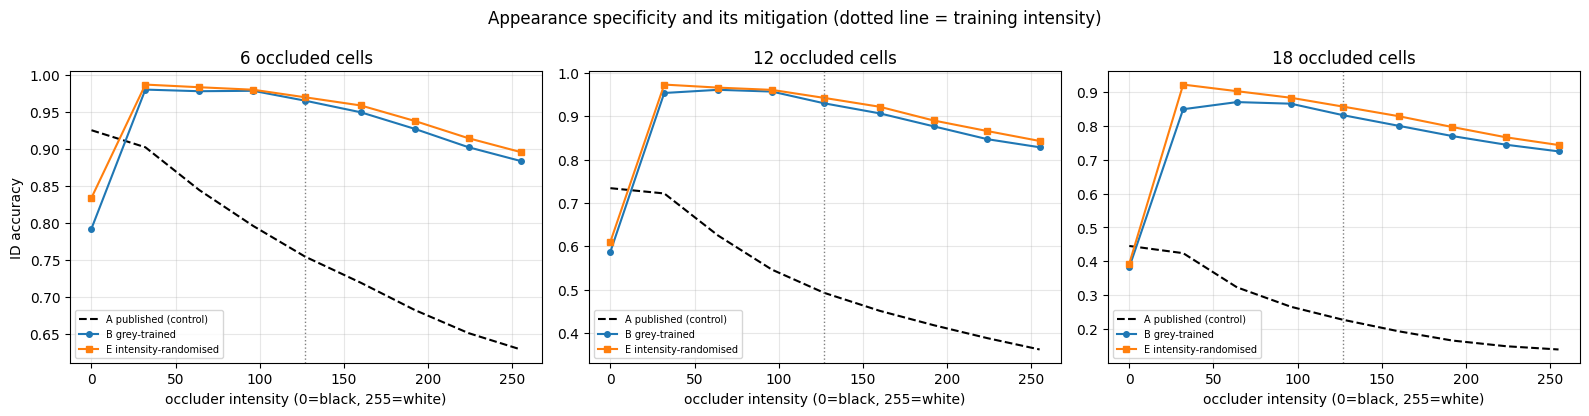


saved -> /content/drive/MyDrive/aruco_p2/artifacts/n6_mechanism_mitigation.json  |  checkpoint /content/drive/MyDrive/aruco_p2/ckpt_n6/arm_E.pt


In [11]:
red = np.mean([summary[(T,'B')][0]-summary[(T,'E')][0] for T in LEVELS])*100
worst_gain = np.mean([summary[(T,'E')][1]-summary[(T,'B')][1] for T in LEVELS])*100
grey_cost = np.mean([summary[(T,'B')][2]-summary[(T,'E')][2] for T in LEVELS])*100

print(f'mean spread reduction (B -> E)      : {red:+.1f} pp')
print(f'mean worst-case gain  (B -> E)      : {worst_gain:+.1f} pp')
print(f'mean cost on grey (training colour) : {grey_cost:+.1f} pp\n')

if worst_gain >= 15 and grey_cost <= 3:
    print('MITIGATION WORKS. You have failure -> mechanism -> fix. Intensity-randomised')
    print('augmentation removes most of the appearance specificity at negligible cost.')
elif worst_gain >= 5:
    print('PARTIAL. Report the fix with its limits — worthwhile but not a full remedy.')
else:
    print('MITIGATION FAILS. That is a stronger negative result: appearance specificity')
    print('survives intensity randomisation, so the model is not simply memorising intensity.')

fig, ax = plt.subplots(1, 3, figsize=(16,4.2))
for i, T in enumerate(LEVELS):
    for arm, st in [('A','k--'),('B','-o'),('E','-s')]:
        ax[i].plot(INTENS, [E1[(T,v)][arm].mean() for v in INTENS], st, ms=4,
                   label={'A':'A published (control)','B':'B grey-trained','E':'E intensity-randomised'}[arm])
    ax[i].axvline(127, color='grey', ls=':', lw=1)
    ax[i].set_xlabel('occluder intensity (0=black, 255=white)')
    ax[i].set_ylabel('ID accuracy' if i==0 else '')
    ax[i].set_title(f'{T} occluded cells'); ax[i].grid(alpha=.3); ax[i].legend(fontsize=7)
plt.suptitle('Appearance specificity and its mitigation (dotted line = training intensity)')
plt.tight_layout(); plt.show()

json.dump({'intensities': INTENS, 'levels': LEVELS,
           'accuracy': {f'{T}_{v}_{a}': float(E1[(T,v)][a].mean())
                        for T in LEVELS for v in INTENS for a in ('A','B','D','E')},
           'spread_reduction_pp': float(red), 'worst_case_gain_pp': float(worst_gain),
           'grey_cost_pp': float(grey_cost), 'viewpoints': DEV, 'heldout_untouched': HELDOUT},
          open(f'{ART}/n6_mechanism_mitigation.json','w'), indent=1)
print(f'\nsaved -> {ART}/n6_mechanism_mitigation.json  |  checkpoint {CK6}/arm_E.pt')

## 10. Held-out confirmation — only if E2 succeeded

`video_6` was used once already, to confirm the N5 claims. Using it again is defensible **only**
because arm E is trained with a fixed recipe and evaluated once, with no tuning against it. If you
find yourself wanting to adjust anything after seeing these numbers, stop — that would make it a
development set.

Skip this cell entirely if the mitigation failed.

In [12]:
RUN_HELDOUT = False     # set True only when the design is frozen

if RUN_HELDOUT:
    HS = {(T,v): {'x':[], 'id':[], 'frame':[]} for T in LEVELS for v in INTENS}
    for f, j in pairs_for(HELDOUT)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{HELDOUT}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            for T, L in LEVELS.items():
                box = occluder_box(img, cn, L, 'edge', key, mid)
                for v in INTENS:
                    oi, om = apply_occluder(img, box, v)
                    x32, _ = prepare(oi, om, cn)
                    if x32 is None: continue
                    HS[(T,v)]['x'].append((x32*255).astype(np.uint8))
                    HS[(T,v)]['id'].append(mid); HS[(T,v)]['frame'].append(key)
    for k in HS:
        for kk in HS[k]: HS[k][kk] = np.array(HS[k][kk])

    print(f"{'cells':>6}{'arm':>5}" + ''.join(f'{v:>8}' for v in INTENS) + f"{'spread':>9}")
    print('-'*(11+8*len(INTENS)+9))
    for T in LEVELS:
        for arm in ('A','B','E'):
            acc = [ (dec_soft(decode_published(HS[(T,v)]['x']) if arm=='A'
                              else decode_torch(models[arm], HS[(T,v)]['x'])) == HS[(T,v)]['id']).mean()
                    for v in INTENS ]
            print(f'{T:>6}{arm:>5}' + ''.join(f'{a:>8.1%}' for a in acc)
                  + f'{(max(acc)-min(acc))*100:>8.1f}p')
        print()
else:
    print('Held-out evaluation skipped. Set RUN_HELDOUT = True only when the design is frozen.')

Held-out evaluation skipped. Set RUN_HELDOUT = True only when the design is frozen.
